# Segmentation of Resected Area

<img src="../../img/resection.png">

## 🧪 - Experiment setup

- `fwd`: Forward solution
- `ave`: Measurements
- `ncov`: Noise covariance
- `eig`: Eigenvectors and eigenvalues of the Connectome Lacplacian.
- `resec`: Resection area

In [1]:
# import
import mindmap as mm
from pathlib import Path
import numpy as np
import ants

# readers
dm = mm.io.TutoManager("../../config.yml")
sub = "spike11"

# data
t1_pre = dm.load(sub, "t1w", session="preop", res="cmp", desc="brain")
t1_post = dm.load(sub, "t1w", session="postop", space="individual", desc="brain")
parc = dm.load(sub, "dseg", space="fs", segmentation="multiconn2022", scale="4")

## 🧠 Data

In [3]:
################# Parameters ###################
# configuration
fconfig = "../../papers/spike/configuration.yml" 
sub     = 1

# morpho operators
ksize_opening = 3
ksize_closing = 3
#################################################

reader = mm.io.dataset_reader(fconfig)
data   = reader(sub, "T1-brain", "mri_post", "parc", mri_dtype="ants")

# directories
mm_dir = reader.config["MM_DIR"]
ds_dir = reader.config["DS_DIR"]

# output files (for freeview visualization)
fname_resec = mm_dir/data["sub"]/"resec"/f"{data['sub']}_resection-mask.nii.gz"
fname_diff  = mm_dir/data["sub"]/"resec"/f"{data['sub']}_prepost-diff.mask.nii.gz"
fname_npre  = mm_dir/data["sub"]/"resec"/f"{data['sub']}_hm-pre.nii.gz"
fname_npost = mm_dir/data["sub"]/"resec"/f"{data['sub']}_hm-post.nii.gz"

DATA SUMMARY
Dataset: spike
Subject: sub-pat01
Retrieved objects:
- mri_post
- T1-brain
- parc
Missing objects:


⚙️ <font color=green>**Close GM mask**</font>

In [7]:
# prepare GM mask
gm_mask = ants.from_numpy(
    data = mm.anatomy.parcellation.create_mask(parc).get_fdata(),
    origin = t1_pre.origin,
    spacing = t1_pre.spacing,
    direction = t1_pre.direction,
    has_components = t1_pre.has_components,
)

gm_mask = ants.morphology(gm_mask, "close", radius=5, mtype="binary", shape="ball")

🌟 **Visualize MRIs**

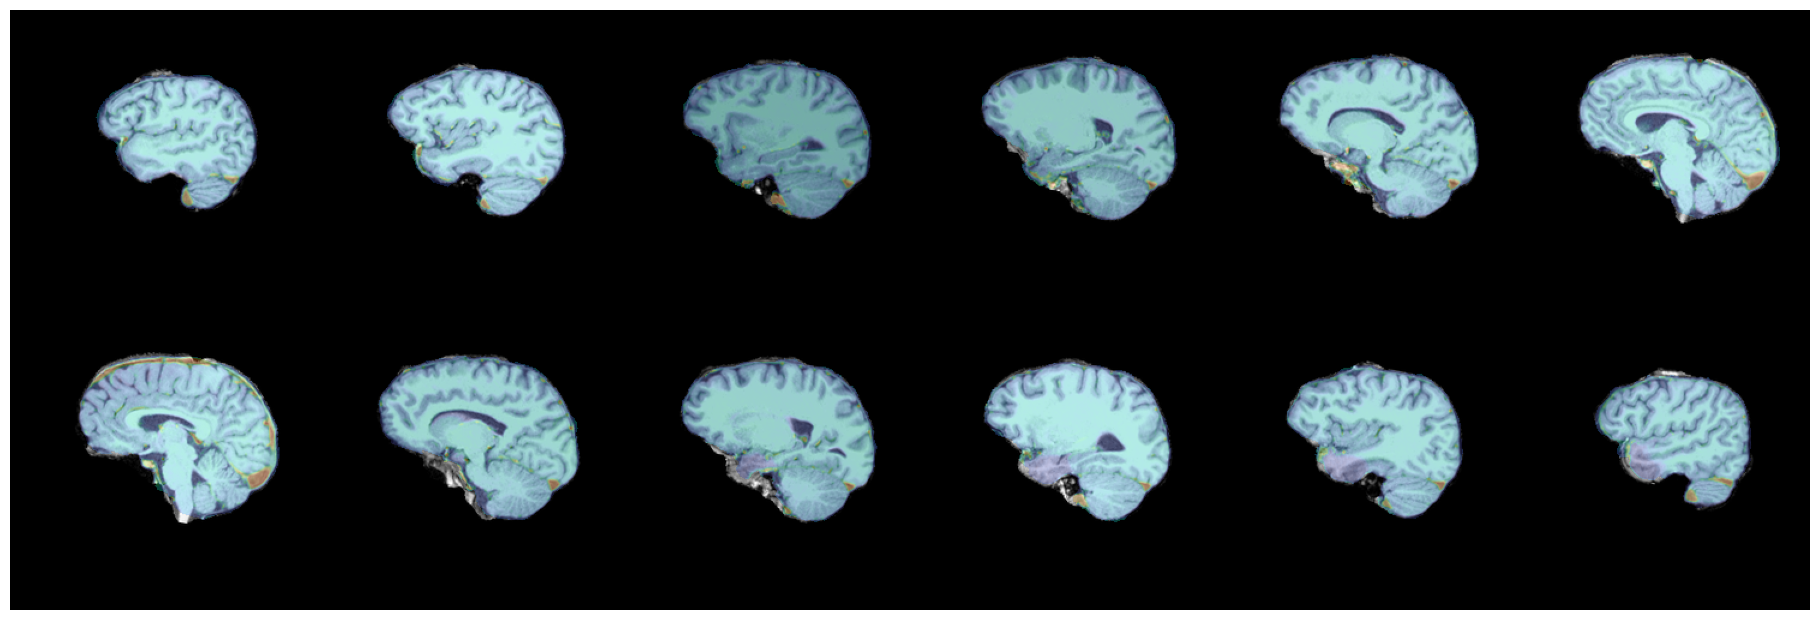

In [8]:
t1_pre.plot(overlay=t1_post, overlay_alpha=0.3, ncol=6, figsize=3)

🌟 **Visualize GM mask**

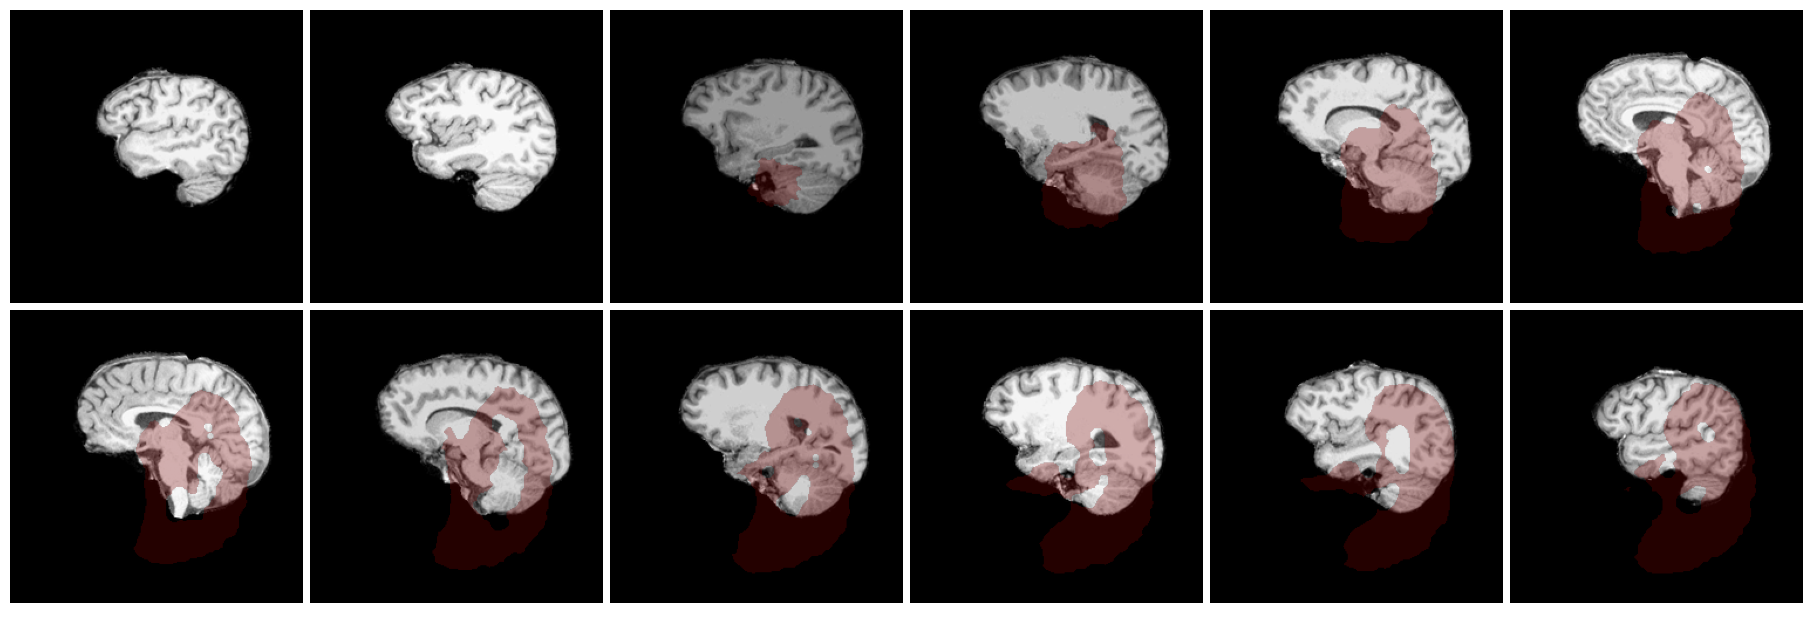

In [9]:
t1_pre.plot(overlay=gm_mask, overlay_alpha=0.3, ncol=6, figsize=3)

## Segmentation of resection area

⚙️ <font color=green>**Rigid registration**</font>: To subtract both images they must first align

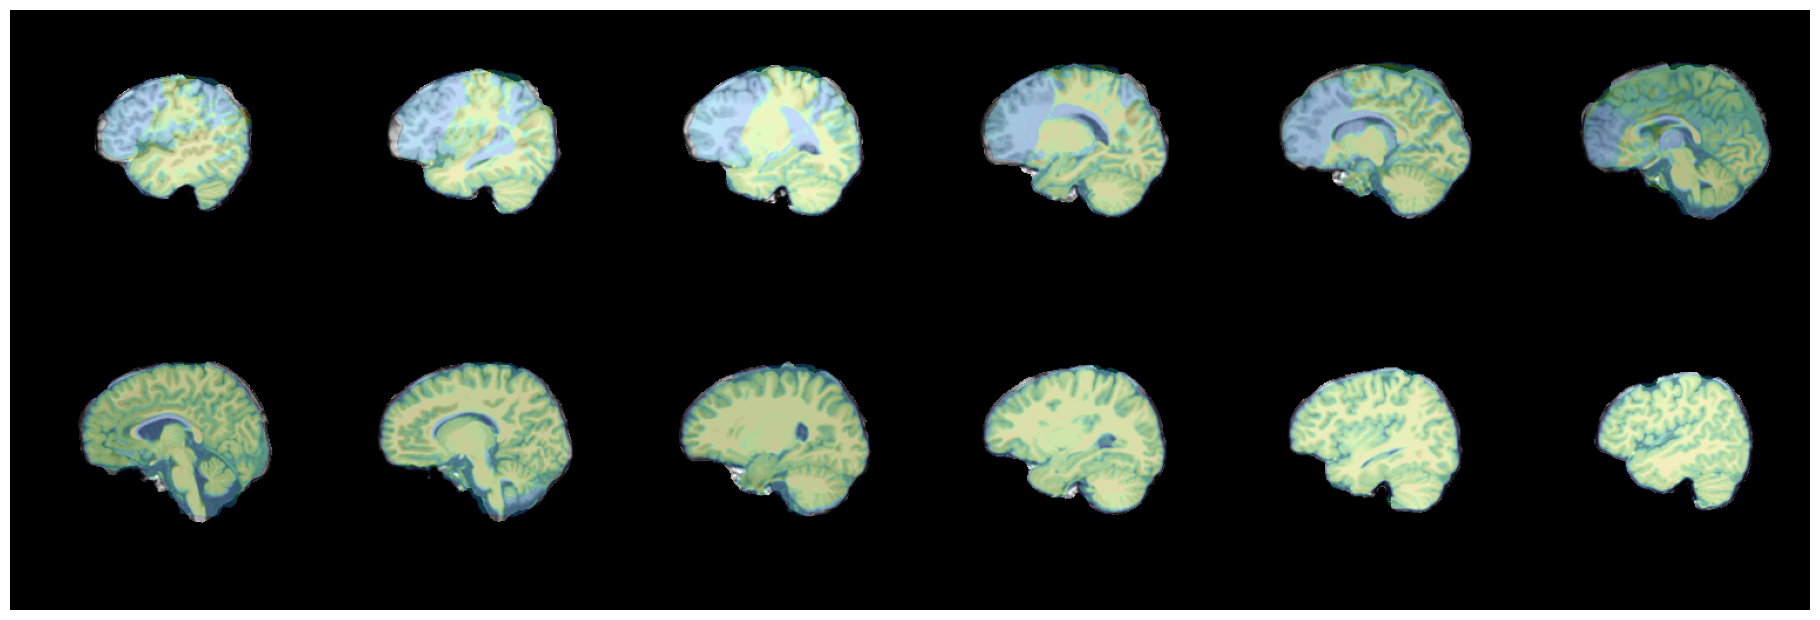

In [7]:
# register
tx = ants.registration(fixed=data["T1-brain"], moving=data["mri_post"], type_of_transform="Rigid")
mri_post = ants.apply_transforms(fixed=data["T1-brain"], moving=data["mri_post"], transformlist=tx["fwdtransforms"])

data["T1-brain"].plot(overlay=mri_post, overlay_alpha=0.3, ncol=6, figsize=3)

⚙️ <font color=green>**Histogram matching**</font>: Both images utilize varying intensities for similar tissues. By matching the histograms, similar tissues will be represented with comparable intensities.

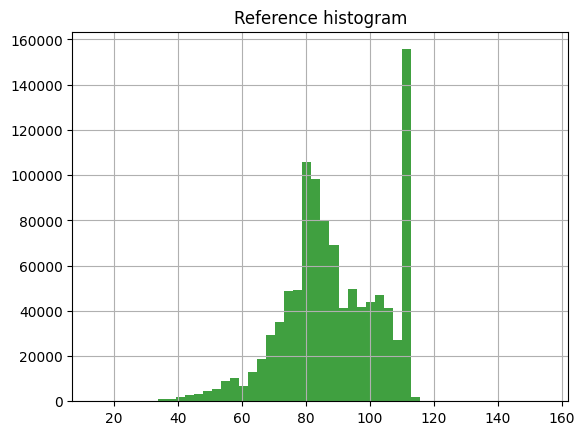

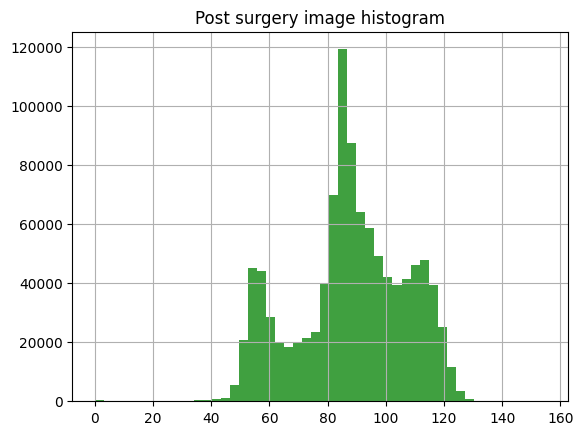

In [8]:
# mask GM area
mri_pre  = data["T1-brain"]*gm_mask
mri_post = mri_post*gm_mask

# match histograms
mri_post = ants.histogram_match_image(mri_post, mri_pre)

# plot
fig = mri_pre.plot_hist(title="Reference histogram")
fig = mri_post.plot_hist(title="Post surgery image histogram")

⚙️ <font color=green>**Compute difference and mask GM area**</font>: We calculate the difference to emphasize the resection area and apply a gray matter mask to prevent highlights caused by misalignments, such as those resulting from variations in skull stripping. These issues typically occur at the brain's border, so they are excluded when focusing solely on the gray matter region.

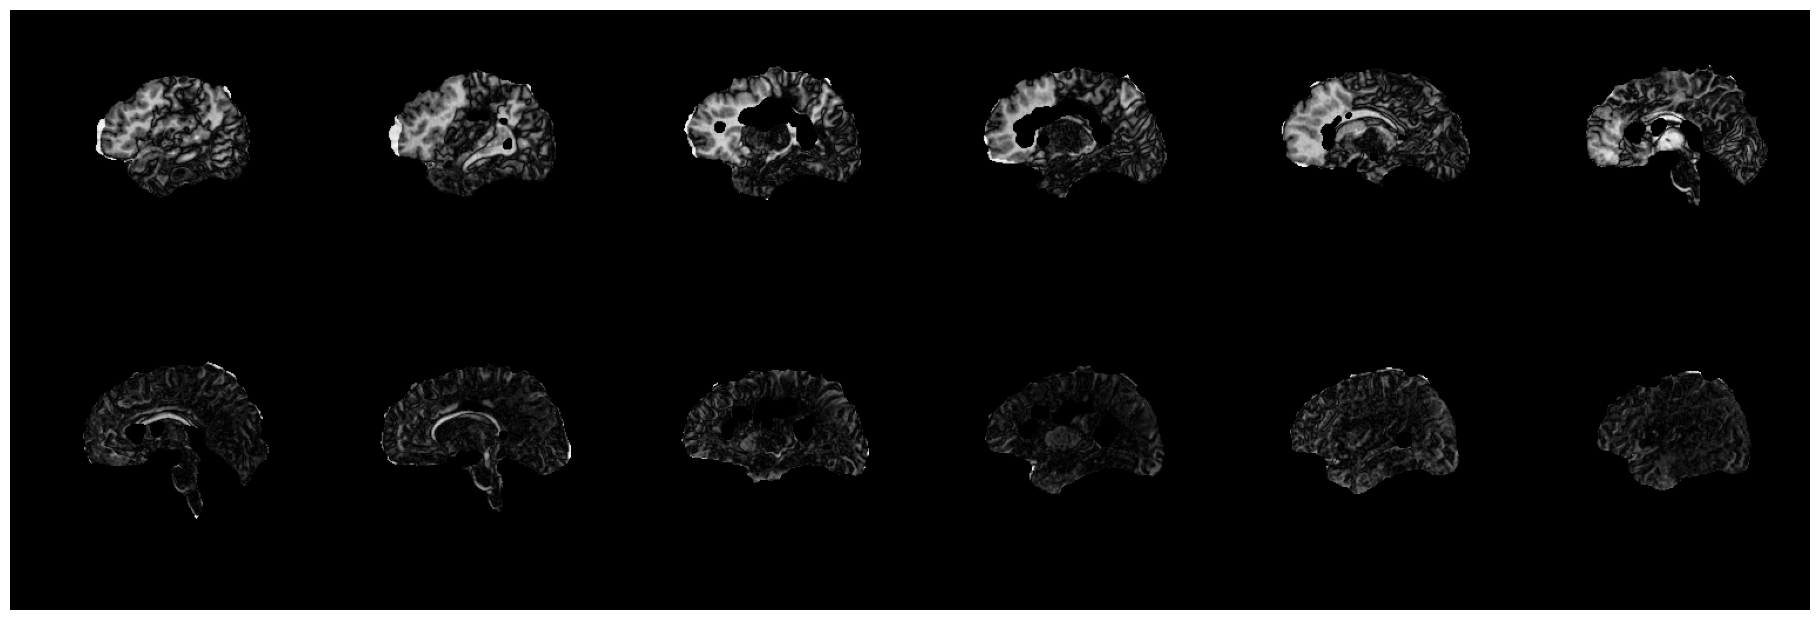

In [9]:
mri_diff = data["T1-brain"]-mri_post
mri_diff = mri_diff.apply(np.abs)

mri_diff = mri_diff * gm_mask

mri_diff.plot(ncol=6, figsize=3)

**<font color=violet>Special cases</font>**
- spike/sub-pat28: Noise at top of the brain considered as resected area + something I can't see in the right hemisphere (solution: clip top of brain and left hemisphere)

In [11]:
if data["name"] == "spike":
    if data['sub'] == "sub-pat28":
        mask = np.ones(mri_diff.shape)
        mask[:,:50,:] = 0
        mask[:125, :,:] = 0     # only left hemisphere
        mri_diff *= mask

💾 **Save Difference Image**:
Only necessary if wanting to visualize in more advanced software.

In [13]:
folder = mm_dir/data["sub"]/"resec"

if not folder.exists():
    folder.mkdir(parents=True)

fname = folder/f"{data['sub']}_diff.nii.gz"
mri_diff.image_write(str(fname))

⚙️ <font color=green>**Binarize Image**</font>: Threshold operation will binarize values above threshold and apply some classic morphological operators to clean the mask.

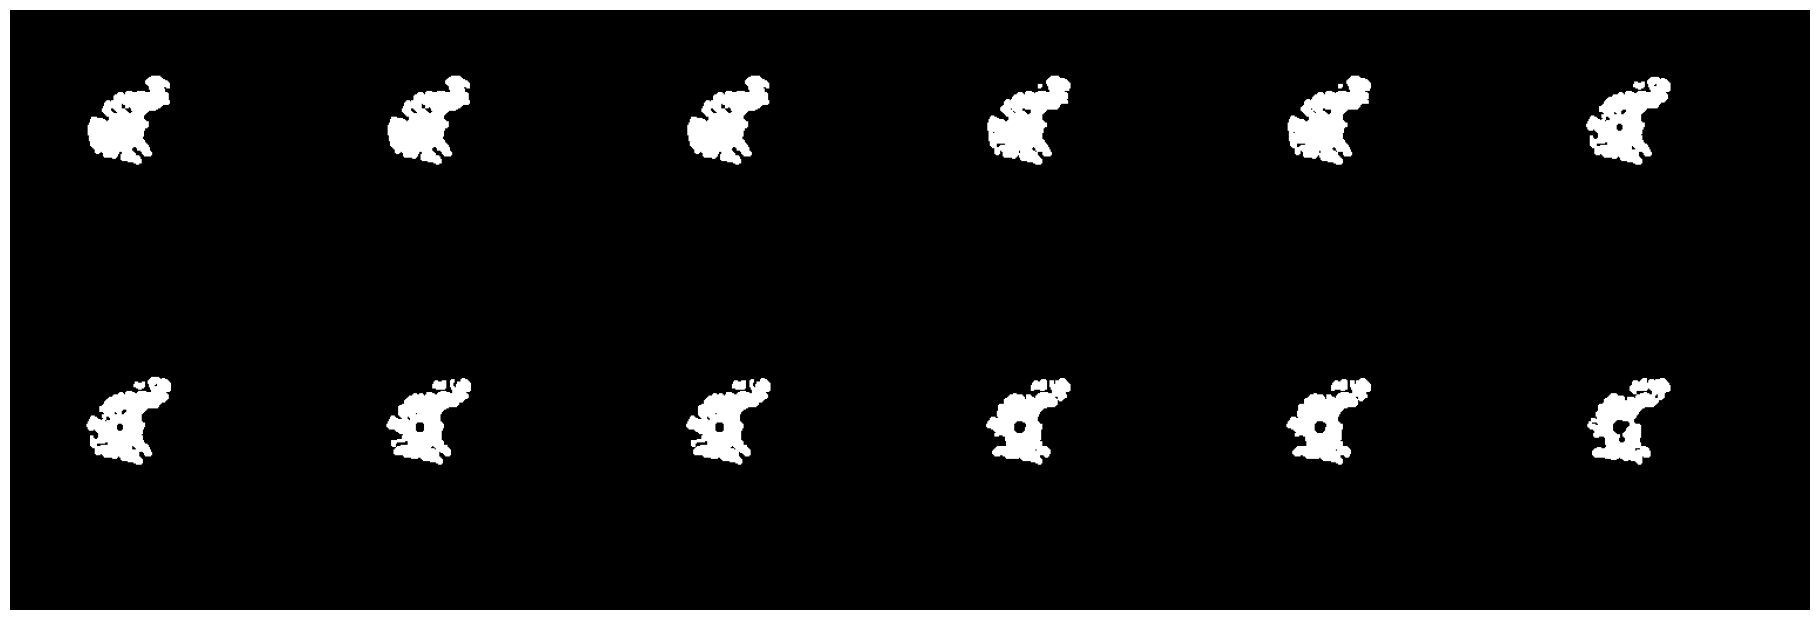

In [14]:
low_thresh  = ants.quantile(mri_diff, q=0.6)

mri_bin = ants.get_mask(mri_diff, low_thresh=low_thresh)
mri_bin = mri_bin

mri_bin.plot(ncol=6, figsize=3)

## 💾 Save Resection mask

In [15]:
# choose which image to save
mri = mri_bin

# save file
folder = mm_dir/data["sub"]/"resec"

if not folder.exists():
    folder.mkdir(parents=True)

fname = folder/f"{data['sub']}_auto-seg.nii.gz"
mri_bin.image_write(str(fname))

print(f"Saved automatic resection for subject {data['sub']}")

Saved automatic resection for subject sub-pat01
